# TBG atomic relaxation from first-principles density functional theory

The following notebook shows how to read the relaxed TBG structures, plot a displacement field of the in-plane relaxation, and analyze trends in the relaxation as a function of the twist angle. `Matplotlib` and `numpy` are required.

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches

In [2]:
def angles(N):
    """
    Return the angle corresponding to an integer N (see angles.txt)
    """
    return np.round(
        np.arccos(
            ((N - 1) ** 2 + 4 * N * (N - 1) + N ** 2) / (2 * ((N - 1) ** 2 + N * (N - 1) + N ** 2))
        ) * 180 / np.pi, 
        10
    )

1014 1014
0.0010999999999999899


Text(0.5, 1, '$\\theta=5.086^\\circ$')

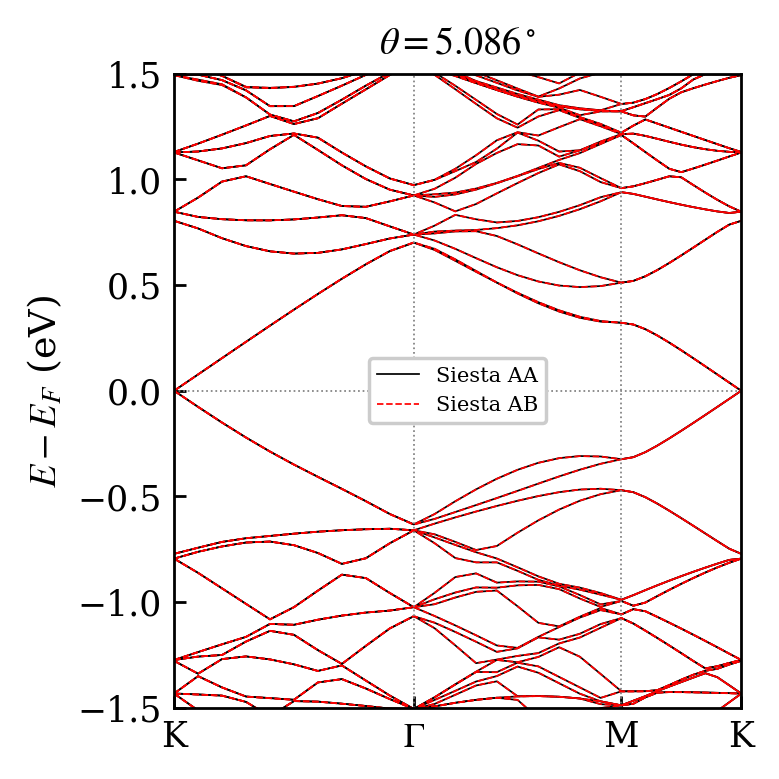

In [18]:
# Ignore variable names, they are copy pasted from one of my earlier notebooks
# Load band structure data
N = 7
# michele = np.loadtxt(f"corrected-bands/N_{N}-AA.txt")
siesta_relaxed_AA = np.loadtxt(f"Gamma20/{N}/bands.dat")
siesta_relaxed_AB = np.loadtxt(f"AB_calculations/{N}/bands.dat")

# Final shape is (N_bands, Nkpoints)
Nkpoints = 31
# michele_k = michele[:, 0].reshape((-1, Nkpoints))
# michele_E = michele[:, 1].reshape((-1, Nkpoints))
siesta_relaxed_AA_k = siesta_relaxed_AA[:, 0].reshape((-1, Nkpoints))
siesta_relaxed_AA_E = siesta_relaxed_AA[:, 1].reshape((-1, Nkpoints))
siesta_relaxed_AB_k = siesta_relaxed_AB[:, 0].reshape((-1, Nkpoints))
siesta_relaxed_AB_E = siesta_relaxed_AB[:, 1].reshape((-1, Nkpoints))
closest_index_AA = np.argmin(np.abs(siesta_relaxed_AA_E[:, 0]))
closest_index_AB = np.argmin(np.abs(siesta_relaxed_AB_E[:, 0]))
siesta_relaxed_AA_E -= siesta_relaxed_AA_E[closest_index_AA][0]
siesta_relaxed_AB_E -= siesta_relaxed_AB_E[closest_index_AB][0]

print(closest_index_AA, closest_index_AB)
print(np.max(np.abs(siesta_relaxed_AA_E[closest_index_AA - 8:closest_index_AA + 12] - siesta_relaxed_AB_E[closest_index_AA - 8:closest_index_AA + 12])))

# Plot bands, use j to select lowest band to plot
x_axis = np.concatenate(
    (
        np.arange(0, Nkpoints // 3 * np.sqrt(3) / 2, np.sqrt(3) / 2), 
        np.arange(Nkpoints // 3 * np.sqrt(3) / 2, Nkpoints // 3 * np.sqrt(3) / 2 + Nkpoints // 6, 1 / 2), 
        np.arange(Nkpoints // 3 * np.sqrt(3) / 2 + Nkpoints // 6, Nkpoints // 2 + 0.01 + Nkpoints // 3 * np.sqrt(3) / 2, 1)
    )
)
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(3, 3), dpi=250, layout="constrained")
j = closest_index_AA - 25
for i, _ in enumerate(siesta_relaxed_AA_k[j:closest_index_AA + 25]):
    if i == 0:
        ax.plot(siesta_relaxed_AA_k[i + j][:], siesta_relaxed_AA_E[i + j], color="k", linewidth=0.5, label=r"Siesta AA")
    else:
        ax.plot(siesta_relaxed_AA_k[i + j][:], siesta_relaxed_AA_E[i + j], color="k", linewidth=0.5)

for i, _ in enumerate(siesta_relaxed_AB_k[j:closest_index_AB + 25]):
    if i == 0:
        ax.plot(siesta_relaxed_AA_k[i + j][:], siesta_relaxed_AB_E[i + j], color="r", linewidth=0.5, linestyle="--", label="Siesta AB")
    else:
        ax.plot(siesta_relaxed_AA_k[i + j][:], siesta_relaxed_AB_E[i + j], color="r", linewidth=0.5, linestyle="--")

# for i, _ in enumerate(michele_k[j:closest_index_AA + 25]):
#     if i == 0:
#         ax.plot(michele_k[i + j], michele_E[i + j], color="b", linewidth=0.5, linestyle=":", label=r"Michele")
#     else:
#         ax.plot(michele_k[i + j], michele_E[i + j], color="b", linewidth=0.5, linestyle=":")

# print(unrelaxed_E[zero_band][10] - unrelaxed_E[zero_band][0])
ax.set_ylim(-1.5,1.5)
ax.set_xlim(siesta_relaxed_AA_k[closest_index_AB][0], siesta_relaxed_AA_k[closest_index_AB][-1])
x_ticks = np.array([x_axis[0], x_axis[Nkpoints // 3], x_axis[2 * Nkpoints // 3], x_axis[Nkpoints - 1]])
xtick_labels = [r"K", r"$\Gamma$", "M", "K"]
ax.set_xticks(
    [siesta_relaxed_AA_k[1][0], siesta_relaxed_AA_k[1][Nkpoints // 3], siesta_relaxed_AA_k[1][2 * Nkpoints // 3], siesta_relaxed_AA_k[1][Nkpoints - 1]], 
    xtick_labels
)
# ax.set_yticks(np.arange(-0.4, 0.41, 0.2), [fr"${str(i)}$" for i in np.round(np.arange(-0.4, 0.41, 0.2), 1)])
ax.axvline(siesta_relaxed_AA_k[1][Nkpoints // 3], linestyle=":", color="grey", linewidth=0.5)
ax.axvline(siesta_relaxed_AA_k[1][2 * Nkpoints // 3], linestyle=":", color="grey", linewidth=0.5)
ax.axhline(0, linestyle=":", color="grey", linewidth=0.5)
ax.set_ylabel(r"$E - E_F$ (eV)", fontsize=11)
ax.legend(fontsize=6, loc="best", framealpha=1)
ax.tick_params(which="both", direction="in", labelsize=10)
ax.set_title(fr"$\theta={np.round(angles(N), 3)}^\circ$", y=1, fontsize=11)
# ax.yaxis.set_minor_locator(MultipleLocator(0.1))

# ax.scatter(relaxed_k[4374][60], relaxed_E[4374][60])
# plt.savefig(f"relaxation-comparisons/N_{N}_bands_relaxation_comparison.png", bbox_inches="tight", dpi=250)

In [10]:
N = 7
moire_a1 = np.loadtxt(f"{N}/Graphene.XV", usecols=[0, 1, 2], max_rows=1) * 0.529177249  # Angstroms
moire_a2 = np.loadtxt(f"{N}/Graphene.XV", skiprows=1, usecols=[0, 1, 2], max_rows=1) * 0.529177249  # Angstroms
relaxed_atom_pos = np.loadtxt(f"{N}/Graphene.XV", skiprows=4, usecols=[2, 3, 4]) * 0.529177249  # Angstroms
print(np.linalg.norm(moire_a1) * 0.05 / 1.42)
print(moire_a1 * 0.05 / 1.42, moire_a2 * 0.05 / 1.42, moire_a1 + moire_a2)

with open("wfsx_idxs.json", "r") as file:
    idxs = json.load(file)
wfsx_idxs = np.arange(idxs[str(N)]["start"] - 8, idxs[str(N)]["end"] + 8)
sublattices = range(1, 5)

# Define the grid
min_x = int(np.round(0.8 * moire_a1[0], 0))
max_x = int(np.round(3.75 * moire_a1[0], 0))
min_y = int(np.round(0.2 * moire_a2[1], 0))
max_y = int(np.round(2.75 * moire_a2[1], 0))
if N == 2:
    min_x = int(np.round(0.5 * moire_a1[0], 0))
    max_x = int(np.round(4.5 * moire_a1[0], 0))
    min_y = int(np.round(-0.9 * moire_a2[1], 0))
    max_y = int(np.round(2.95 * moire_a2[1], 0))
if N == 3:
    min_x = int(np.round(0.71 * moire_a1[0], 0))
    max_x = int(np.round(3.99 * moire_a1[0], 0))
    min_y = int(np.round(-0.1 * moire_a2[1], 0))
    max_y = int(np.round(2.7 * moire_a2[1], 0))
if N == 4:
    min_x = int(np.round(0.71 * moire_a1[0], 0))
    max_x = int(np.round(3.95 * moire_a1[0], 0))
    min_y = int(np.round(0.0 * moire_a2[1], 0))
    max_y = int(np.round(2.7 * moire_a2[1], 0))
if N == 5:
    min_x = int(np.round(0.8 * moire_a1[0], 0))
    max_x = int(np.round(3.85 * moire_a1[0], 0))
    min_y = int(np.round(0.05 * moire_a2[1], 0))
    max_y = int(np.round(2.71 * moire_a2[1], 0))
if N == 6:
    min_x = int(np.round(0.8 * moire_a1[0], 0))
    max_x = int(np.round(3.85 * moire_a1[0], 0))
    min_y = int(np.round(0.05 * moire_a2[1], 0))
    max_y = int(np.round(2.75 * moire_a2[1], 0))
if N == 7:
    min_x = int(np.round(0.8 * moire_a1[0], 0))
    max_x = int(np.round(3.82 * moire_a1[0], 0))
    min_y = int(np.round(0.1 * moire_a2[1], 0))
    max_y = int(np.round(2.75 * moire_a2[1], 0))
if N == 8:
    min_x = int(np.round(0.8 * moire_a1[0], 0))
    max_x = int(np.round(3.8 * moire_a1[0], 0))
    min_y = int(np.round(0.15 * moire_a2[1], 0))
    max_y = int(np.round(2.75 * moire_a2[1], 0))
min_z = 16
max_z = 24
N_x = max_x - min_x
N_y = max_y - min_y
N_z = max_z - min_z

while N_x < 280:
    N_x *= 2
    N_y *= 2
# N_x *= 10
# N_y *= 10

N_x += 1
N_y += 1

0.9761547205236765
[ 0.97519347 -0.04330986  0.        ] [0.52510417 0.82288738 0.        ] [42.60845293 22.14000159  0.        ]


min: 0.00269257516938987, max: 0.016674141586011857
min: 1.898513527346069e-05, max: 0.14809929436073332


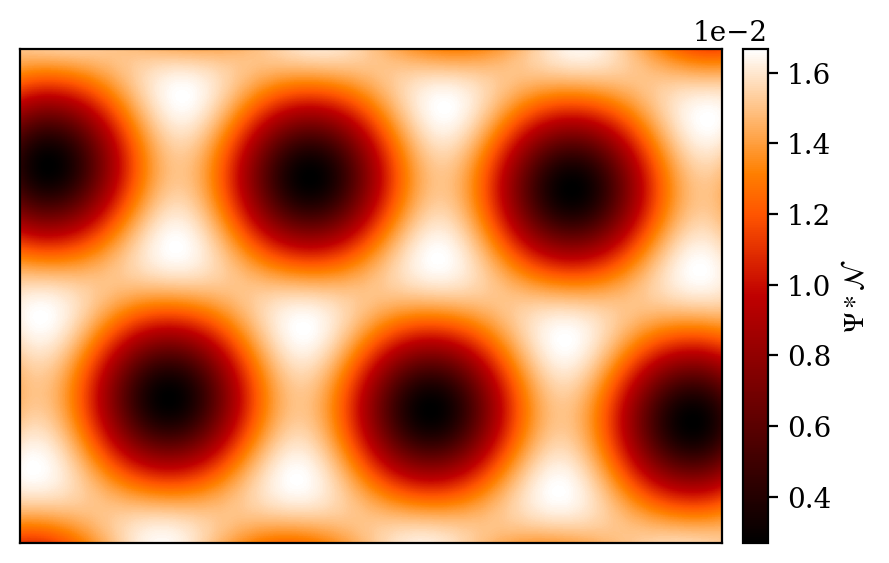

In [16]:
# Plot squared wfsx summed along z
summed_squared_wfsx_10 = np.zeros(N_x * N_y)
start_idx = 10
end_idx = 12
for wfsx_idx in wfsx_idxs[start_idx:end_idx]:
    summed_squared_wfsx_10 += np.loadtxt(f"{N}/Gamma_summed_squares/Gamma_wfsx{wfsx_idx}.txt")[:, 2]
summed_squared_wfsx_10 = summed_squared_wfsx_10.reshape(N_x, -1)
sigma = 10
conv = ndimage.gaussian_filter(summed_squared_wfsx_10, sigma=sigma, mode="wrap", cval=0.0, truncate=3.0)
left_pad = 20 
right_pad = 20 
top_pad = 20 
bottom_pad = 20

print(f"min: {np.min(conv[left_pad:-right_pad, bottom_pad:-top_pad])}, max: {np.max(conv[left_pad:-right_pad, bottom_pad:-top_pad])}")
print(f"min: {np.min(summed_squared_wfsx_10)}, max: {np.max(summed_squared_wfsx_10)}")

moire_vertex_1 = (moire_a1 + moire_a2)[:2] - np.array([min_x, min_y]) - np.array([left_pad, bottom_pad])
moire_vertex_2 = moire_a1[:2] + (moire_a1 + moire_a2)[:2] - np.array([min_x, min_y]) - np.array([left_pad, bottom_pad])
moire_vertex_3 = moire_a2[:2] + (moire_a1 + moire_a2)[:2] - np.array([min_x, min_y]) - np.array([left_pad, bottom_pad])
moire_vertex_4 = moire_a1[:2] + moire_a2[:2] + (moire_a1 + moire_a2)[:2] - np.array([min_x, min_y]) - np.array([left_pad, bottom_pad])

# Add the subplots
f, ax = plt.subplots(1, 1, figsize=(4.5, 2.7), dpi=200, layout="constrained")
p = ax.imshow(conv[left_pad:-right_pad, bottom_pad:-top_pad].T, origin="lower", cmap="gist_heat")
# p = ax.imshow(summed_squared_wfsx_10[left_pad:-right_pad, bottom_pad:-top_pad].T, origin="lower", cmap="gist_heat")
# ax.plot(hexagon_vertices[:, 0], hexagon_vertices[:, 1], lw=5, color="w")
ax.set_aspect("equal")
# ax.set_xticks(np.arange(0, N_x - left_pad - right_pad, 80), np.arange(0, N_x - left_pad - right_pad, 80) // 4)
# ax.set_yticks(np.arange(0, N_y - top_pad - bottom_pad, 40), np.arange(0, N_y - top_pad - bottom_pad, 40) // 4)
ax.set_xticks([], [])
ax.set_yticks([], [])

cbar = f.colorbar(p, ax=ax, label=r"$\Psi * \mathcal{N}$", pad=-0.04)
cbar.formatter.set_powerlimits((0, 0))

min: 0.002688967645058142, max: 0.016646172364888252
min: 3.455194449237091e-06, max: 0.14152461923057774


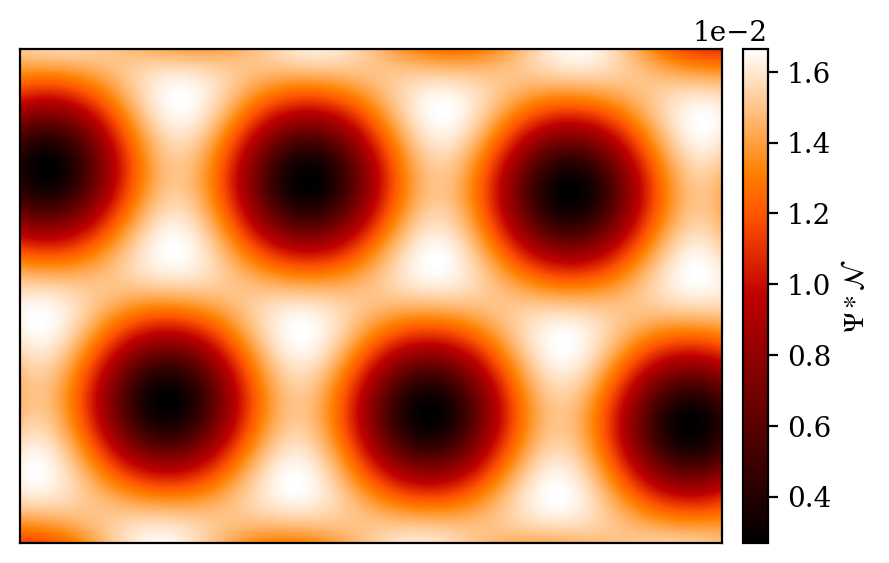

In [15]:
# Plot squared wfsx summed along z
summed_squared_wfsx_10 = np.zeros(N_x * N_y)
start_idx = 10
end_idx = 12
for wfsx_idx in wfsx_idxs[start_idx:end_idx]:
    summed_squared_wfsx_10 += np.loadtxt(f"{N}/Gamma_AB_wfsx{wfsx_idx}.txt")[:, 2]
summed_squared_wfsx_10 = summed_squared_wfsx_10.reshape(N_x, -1)
sigma = 10
conv = ndimage.gaussian_filter(summed_squared_wfsx_10, sigma=sigma, mode="wrap", cval=0.0, truncate=3.0)
left_pad = 20 
right_pad = 20 
top_pad = 20 
bottom_pad = 20

print(f"min: {np.min(conv[left_pad:-right_pad, bottom_pad:-top_pad])}, max: {np.max(conv[left_pad:-right_pad, bottom_pad:-top_pad])}")
print(f"min: {np.min(summed_squared_wfsx_10)}, max: {np.max(summed_squared_wfsx_10)}")

moire_vertex_1 = (moire_a1 + moire_a2)[:2] - np.array([min_x, min_y]) - np.array([left_pad, bottom_pad])
moire_vertex_2 = moire_a1[:2] + (moire_a1 + moire_a2)[:2] - np.array([min_x, min_y]) - np.array([left_pad, bottom_pad])
moire_vertex_3 = moire_a2[:2] + (moire_a1 + moire_a2)[:2] - np.array([min_x, min_y]) - np.array([left_pad, bottom_pad])
moire_vertex_4 = moire_a1[:2] + moire_a2[:2] + (moire_a1 + moire_a2)[:2] - np.array([min_x, min_y]) - np.array([left_pad, bottom_pad])

# Add the subplots
f, ax = plt.subplots(1, 1, figsize=(4.5, 2.7), dpi=200, layout="constrained")
p = ax.imshow(conv[left_pad:-right_pad, bottom_pad:-top_pad].T, origin="lower", cmap="gist_heat")
# p = ax.imshow(summed_squared_wfsx_10[left_pad:-right_pad, bottom_pad:-top_pad].T, origin="lower", cmap="gist_heat")
# ax.plot(hexagon_vertices[:, 0], hexagon_vertices[:, 1], lw=5, color="w")
ax.set_aspect("equal")
# ax.set_xticks(np.arange(0, N_x - left_pad - right_pad, 80), np.arange(0, N_x - left_pad - right_pad, 80) // 4)
# ax.set_yticks(np.arange(0, N_y - top_pad - bottom_pad, 40), np.arange(0, N_y - top_pad - bottom_pad, 40) // 4)
ax.set_xticks([], [])
ax.set_yticks([], [])

cbar = f.colorbar(p, ax=ax, label=r"$\Psi * \mathcal{N}$", pad=-0.04)
cbar.formatter.set_powerlimits((0, 0))

In [9]:
k_bottom = relaxed_E[zero_band - 2][0]
k_top = relaxed_E[zero_band + 0][0]
print(f"VASP K gap: {1000 * (k_top - k_bottom)} meV")

VASP K gap: 0.4999999999997229 meV


In [11]:
zero_band

4376

In [12]:
k_bottom = unrelaxed_E[zero_band - 2][0]
k_top = unrelaxed_E[zero_band + 0][0]
print(f"Siesta K gap: {1000 * (k_top - k_bottom)} meV")

Siesta K gap: 0.0999999999999994 meV


In [3]:
# siesta_relaxed_bandwidth = {
#     "relaxed": {
#         21.79: 7.3875,  # I didn't bother to compute this one bc only 1 k point
#         9.43: 2.8498,
#         7.34: 2.1065,
#         6.01: 1.6476,
#         5.08: 1.3328,
#         4.41: 1.1071,
#         3.89: 0.9375,
#         2.45: 0.4654,
#     }
# }

In [14]:
# l = lattice vectors in Ang, u = unrelaxed, r = relaxed

N = 31
# vasp_l = read(f"atomic-pos/N_{N}/POSCAR").get_cell()
# vasp_u = read(f"atomic-pos/N_{N}/POSCAR").get_positions()
# vasp_r = read(f"atomic-pos/N_{N}/CONTCAR").get_positions()

n_atoms = int(np.loadtxt(f"Gamma20/{N}/Graphene.XV", skiprows=3, max_rows=1).item())
siesta_l = np.loadtxt(f"Gamma20/{N}/structure.fdf", skiprows=2, max_rows=3)
siesta_u = np.loadtxt(f"Gamma20/{N}/structure.fdf", skiprows=17, max_rows=n_atoms, usecols=[0, 1, 2])
siesta_r = np.loadtxt(f"Gamma20/{N}/Graphene.XV", skiprows=4, max_rows=n_atoms, usecols=[2, 3, 4]) * 0.529177249  # KEEP ALL DIGITS
# print(np.allclose(vasp_u[:, :2], siesta_u[:, :2], atol=1e-05))
# print((siesta_r[:, :2] - siesta_u[:, :2])[:10])
# print(np.max(np.linalg.norm(siesta_r[:, :2] - siesta_u[:, :2], axis=1)))
# print(np.max(np.linalg.norm(vasp_r[:, :2] - vasp_u[:, :2], axis=1)))

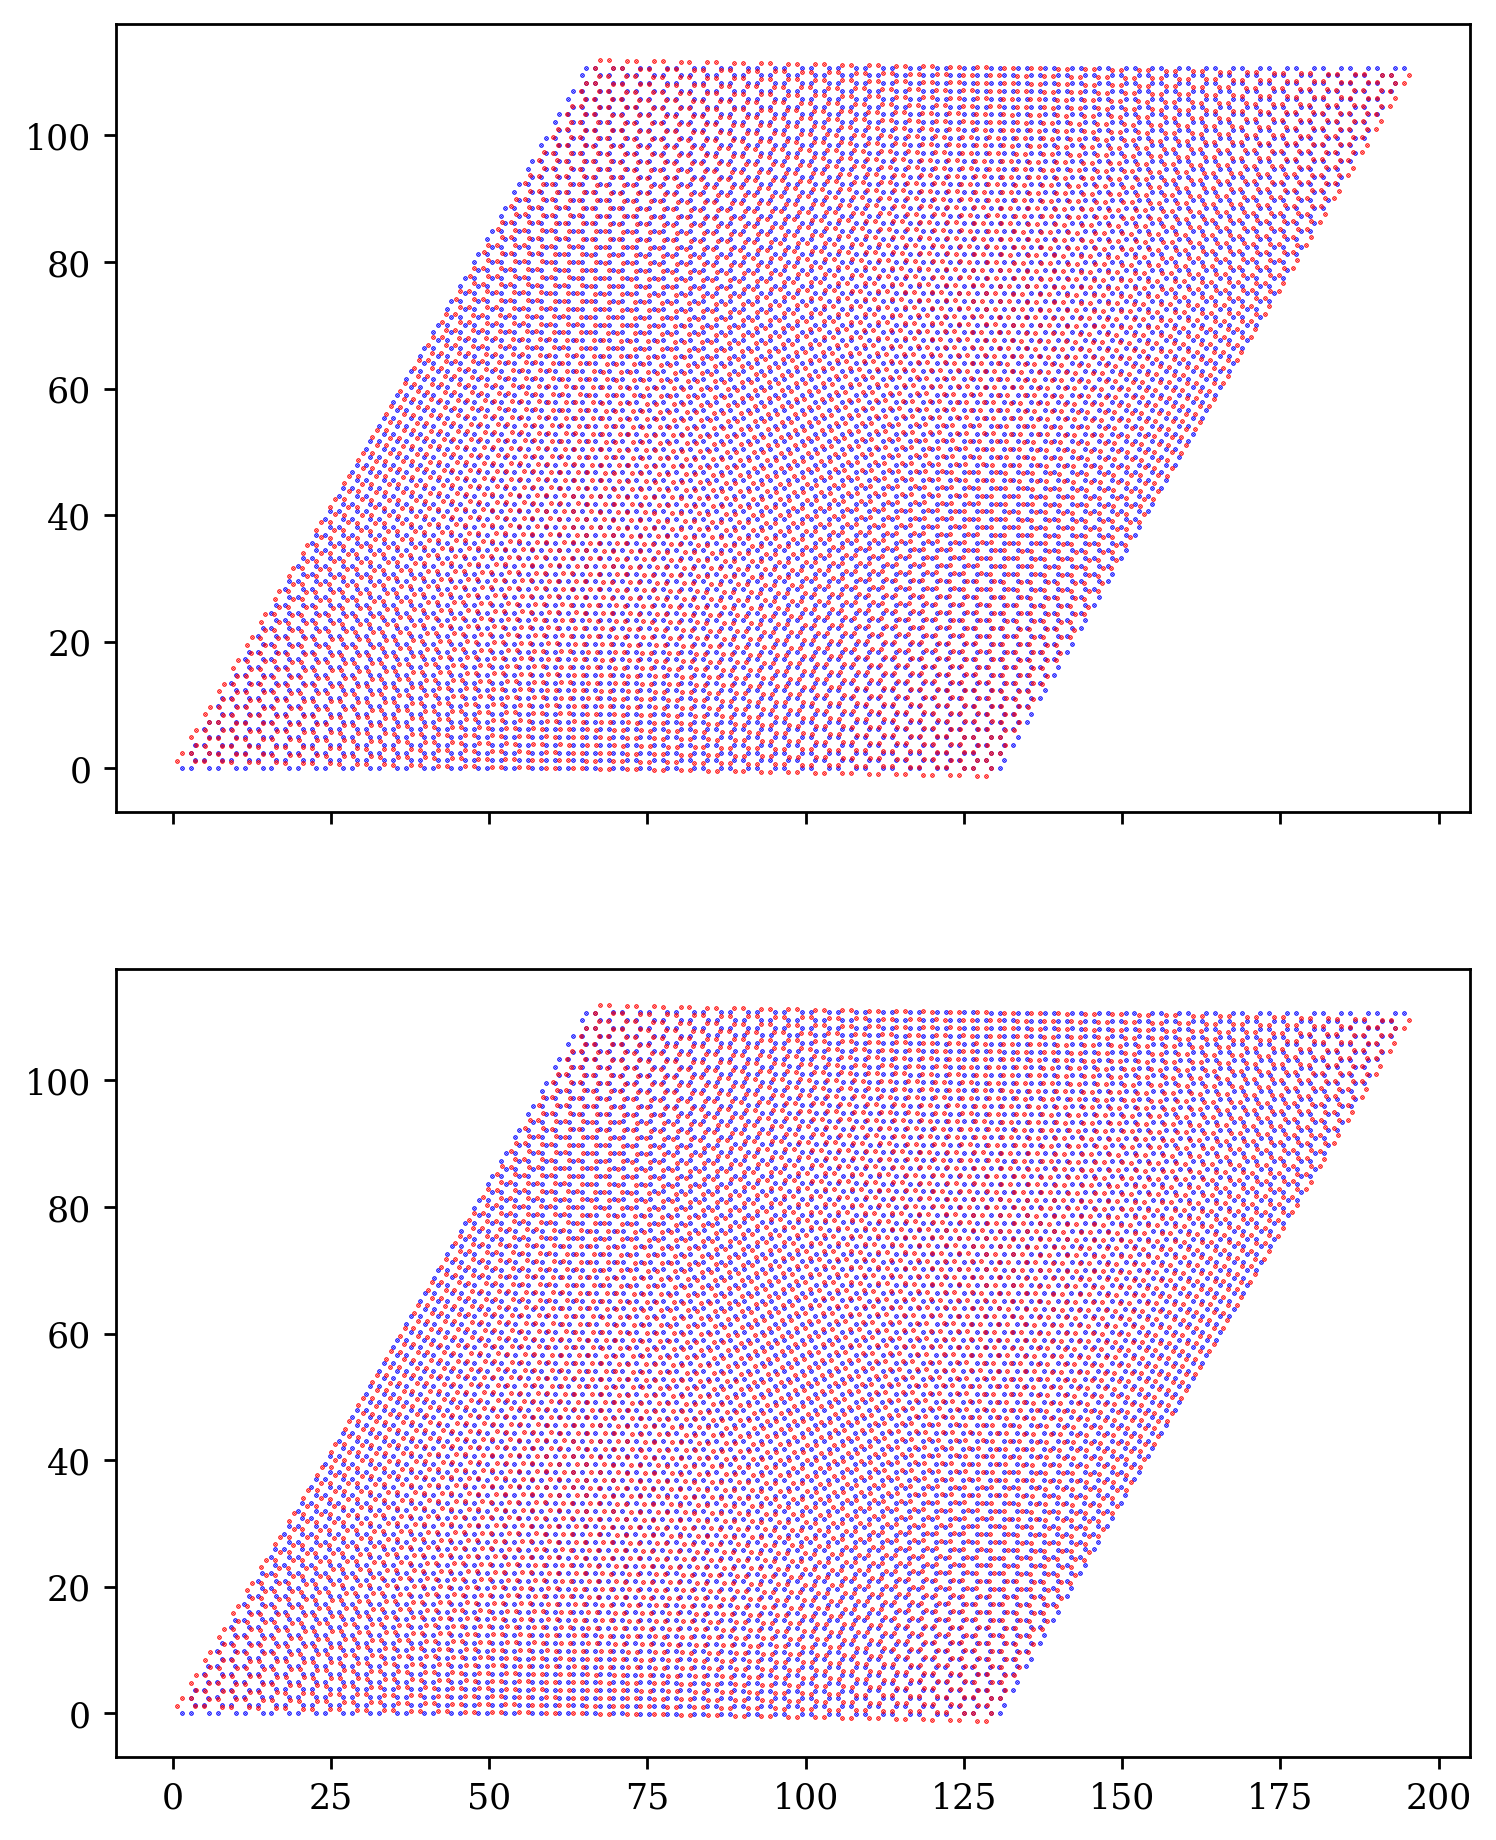

In [17]:
f, ax = plt.subplots(2, 1, sharex=True, sharey=True, dpi=250, figsize=(8, 9))
ax[0].scatter(siesta_u[:n_atoms // 2, 0], siesta_u[:n_atoms // 2, 1], s=0.1, color="b")
ax[0].scatter(siesta_u[n_atoms // 2:, 0], siesta_u[n_atoms // 2:, 1], s=0.1, color="r")
ax[1].scatter(siesta_r[:n_atoms // 2, 0], siesta_r[:n_atoms // 2, 1], s=0.1, color="b")
ax[1].scatter(siesta_r[n_atoms // 2:, 0], siesta_r[n_atoms // 2:, 1], s=0.1, color="r")

for a in ax:
    a.set_aspect("equal")

## Reading the structures

The structure files, both `relaxed-*.fdf` and `rigid-*.fdf`, are written in `Siesta` FDF format. The files contain the lattice vectors, number of atoms, and Cartesian coordinates of the atomic positions, in units of Angstroms. The cell below loads the relaxed and rigid structures for an angle of $1.05^\circ$:

In [15]:
N = 32                                                                                                                # 1.05 degrees
n_atoms = int(np.loadtxt(f"relaxed-atomic-structures/relaxed-{N}.fdf", skiprows=7, max_rows=1, usecols=[1]).item())   # Load number of atoms
lattice = np.loadtxt(f"relaxed-atomic-structures/relaxed-{N}.fdf", skiprows=2, max_rows=3)                            # Load lattice vectors (shape 3 x 3)
relaxed = np.loadtxt(f"relaxed-atomic-structures/relaxed-{N}.fdf", skiprows=17, max_rows=n_atoms, usecols=[0, 1, 2])  # Load relaxed atomic positions (shape n_atoms x 3)
rigid = np.loadtxt(f"relaxed-atomic-structures/rigid-{N}.fdf", skiprows=17, max_rows=n_atoms, usecols=[0, 1, 2])    # Load rigid atomic positions (shape n_atoms x 3)

## Visualizing the in-plane atomic displacements

With the relaxed and rigid atomic structures loaded, we can visualize how atomic relaxation changes the structure of TBG. The following cell plots the atomic displacements ${\bf d}_i = {\bf r}_i - {\bf u}_i$, where ${\bf r}_i$ and ${\bf u}_i$ are the atomic positions of atom $i$ in the relaxed and rigid structure, respectively. The parallelogram in each panel denotes the moire cell, with the AA-stacking regions at the corners.

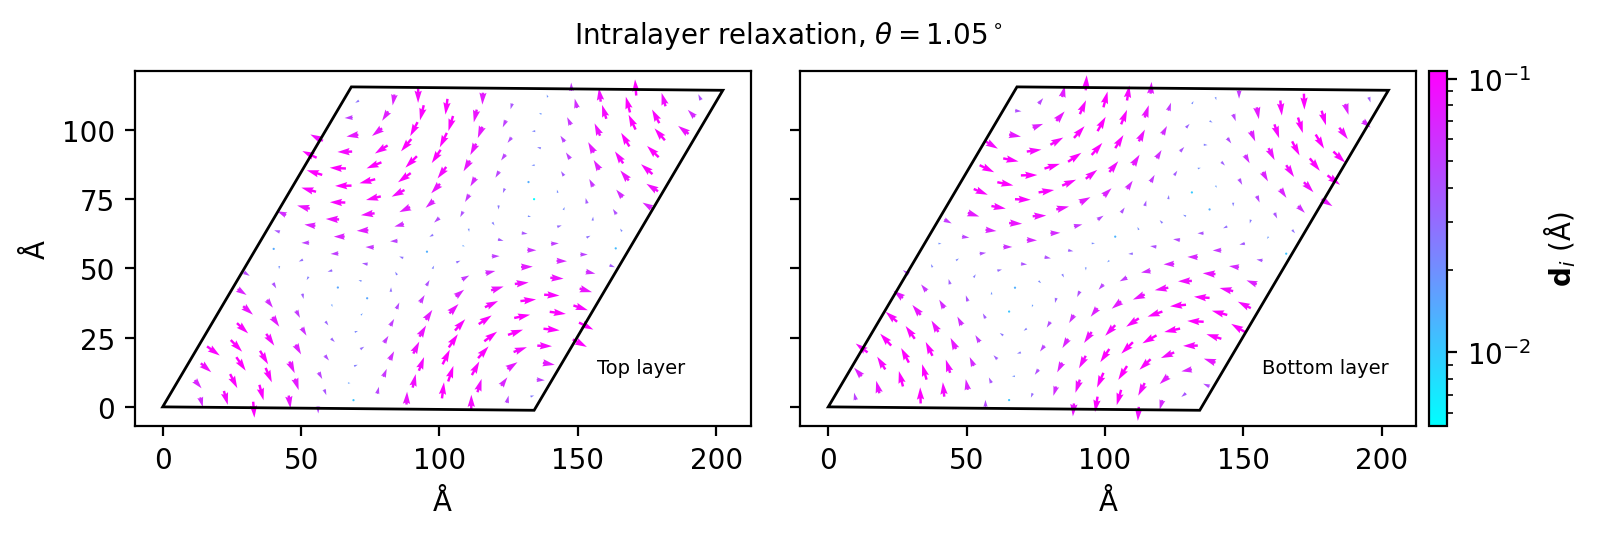

In [56]:
f, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8, 2.5), dpi=200, layout="constrained")

# Scaling for the colors and arrows
cmap = plt.cm.cool
norm = colors.LogNorm(
    vmin=0.05 * np.max(np.linalg.norm(relaxed[:, :2] - rigid[:, :2], axis=1)), 
    vmax=np.max(np.linalg.norm(relaxed[:, :2] - rigid[:, :2], axis=1))
)
scale = 4

# Plot a subset of atomic displacements in sublattice A of each layer for clearer visualization
plot_every = 13

# Top layer atomic displacements
origin = rigid[3 * n_atoms // 4:, :2][::plot_every]
arrow = relaxed[3 * n_atoms // 4:, :2][::plot_every] - origin
p = axes[0].quiver(origin[:, 0], origin[:, 1], arrow[:, 0], arrow[:, 1], np.linalg.norm(arrow, axis=1), scale=scale, cmap=cmap, norm=norm)
axes[0].annotate("Top layer", xy=(0.75, 0.15), xycoords="axes fraction", fontsize=7, color="k")

# Bottom layer atomic displacements
origin = rigid[:n_atoms // 4, :2][::plot_every]
arrow = relaxed[:n_atoms // 4, :2][::plot_every] - origin
p = axes[1].quiver(origin[:, 0], origin[:, 1], arrow[:, 0], arrow[:, 1], np.linalg.norm(arrow, axis=1), scale=scale, cmap=cmap, norm=norm)
axes[1].annotate("Bottom layer", xy=(0.75, 0.15), xycoords="axes fraction", fontsize=7, color="k")

# Draw moire cell
a = lattice[0][:2]
b = lattice[1][:2]
points = [[0, 0], a, a + b, b]

for ax in axes:
    ax.add_patch(patches.Polygon(points, fill=False))
    ax.set_xlabel(r"$\mathrm{\AA}$")
    ax.set_aspect("equal")
axes[0].set_ylabel(r"$\mathrm{\AA}$")

cbar = f.colorbar(p, ax=axes.ravel().tolist(), label=r"${\bf d}_i~(\mathrm{\AA})$", pad=0.01)

plt.suptitle(fr"Intralayer relaxation, $\theta={angles(N):.2f}^\circ$", fontsize=10)
plt.show()

## Displacement trends as a function of twist angle

Lastly, we show how the maximum and mean in-plane atomic displacements evolve as a function of the twist angle.

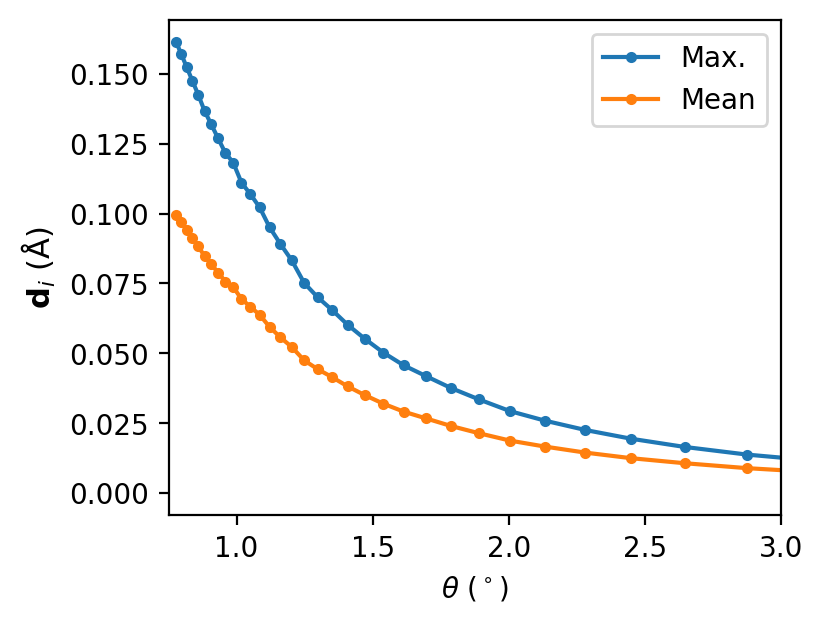

In [67]:
max_displacements = []
mean_displacements = []
Ns = np.arange(2, 44, dtype=int)
for N in Ns:
    n_atoms = num_atoms(N)
    relaxed = np.loadtxt(f"relaxed-atomic-structures/relaxed-{N}.fdf", skiprows=17, max_rows=n_atoms, usecols=[0, 1, 2])
    rigid = np.loadtxt(f"relaxed-atomic-structures/rigid-{N}.fdf", skiprows=17, max_rows=n_atoms, usecols=[0, 1, 2])
    
    xy_displacement = relaxed[:, :2] - rigid[:, :2]
    mean_displacement = np.mean(np.linalg.norm(xy_displacement, axis=1))
    mean_displacements.append(mean_displacement)
    max_displacement = np.amax(np.linalg.norm(xy_displacement, axis=1))
    max_displacements.append(max_displacement)

angle_range = np.array([angles(N) for N in Ns])
fig, ax = plt.subplots(1, 1, figsize=(4, 3), dpi=200, layout="constrained")
ax.plot(angle_range, max_displacements, marker="o", markersize=3, label="Max.")
ax.plot(angle_range, mean_displacements, marker="o", markersize=3, label="Mean")
ax.set_xlim(0.75, 3)

ax.set_ylabel(r"${\bf d}_i$ $(\mathrm{\AA})$", fontsize=11)
ax.set_xlabel(fr"$\theta$ $(^\circ)$")
ax.legend()
plt.show()